# 3. BERTopic

Reads `topic_text` (IFB / follow already stripped). **nr_topics = 24** is the configured BERTopic parameter, not the result.

- Configured topic count: **24** (C13 `nr_topics`)
- Six follow-spam clusters `{3, 5, 18, 20, 22, 23}` were merged into **−1**
- **Final named topics: 18** plus one outlier bucket (−1) = 19 rows in `final_topics.csv`
- Original HDBSCAN outliers and the six merged spam clusters share the −1 bucket

`outputs/topic_model.pkl` (480 MB) is **excluded from the submission package**. BERTopic is **not** refit here.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

def find_root() -> Path:
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "outputs").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot find the project root (need outputs/ and src/). "
        "Open this notebook from the repo, from notebooks/, or from a guideline folder."
    )

ROOT = find_root()
OUT = ROOT / "outputs"
print("ROOT =", ROOT)
print("This notebook reads shipped CSVs and PNGs only.")
print("It does not open IFB.db, does not open any analysis database,")
print("and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.")


ROOT = C:\Users\yosef\OneDrive\שולחן העבודה\IFB-project
This notebook reads shipped CSVs and PNGs only.
It does not open IFB.db, does not open any analysis database,
and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.


configurations 15
final_topics rows 19 named 18 outlier_rows 1
ifb_topword_hits sum 0.0
[embedded figure] coherence_plot.png (108,226 bytes)
[embedded figure] topic_over_time_monthly.png (310,197 bytes)
DONE topic verification


,configuration_name,embedding_model,min_topic_size,n_neighbors,n_components,ngram,reduce_outliers,nr_topics_target,sample_size,n_topics,Topic_num,outlier_count,outlier_pct,topic_size_min,topic_size_median,topic_size_max,coherence,coherence_cv,diversity,ifb_topword_hits,ifb_topwords,runtime_sec,rss_mb_delta,memory_runtime_notes,selected,reject_reason
0,C1_min40_nn15_nc5_uni,all-MiniLM-L6-v2,40,15,5,1-1,0,NaN,64000,183,183,31130,48.64,NaN,NaN,NaN,0.5273,0.5273,0.6419,0,NaN,130.2,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
1,C2_min50_nn15_nc5_uni,all-MiniLM-L6-v2,50,15,5,1-1,0,NaN,64000,144,144,32909,51.42,NaN,NaN,NaN,0.5010,0.5010,0.6568,0,NaN,96.9,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
2,C3_min80_nn15_nc5_uni,all-MiniLM-L6-v2,80,15,5,1-1,0,NaN,64000,94,94,34259,53.53,NaN,NaN,NaN,0.4677,0.4677,0.7437,0,NaN,96.9,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
3,C4_min50_nn10_nc5_uni,all-MiniLM-L6-v2,50,10,5,1-1,0,NaN,64000,170,170,31168,48.70,NaN,NaN,NaN,0.5050,0.5050,0.6564,0,NaN,83.5,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
4,C5_min50_nn30_nc5_uni,all-MiniLM-L6-v2,50,30,5,1-1,0,NaN,64000,142,142,34323,53.63,NaN,NaN,NaN,0.5128,0.5128,0.6309,0,NaN,120.9,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
5,C6_min50_nn15_nc5_bi,all-MiniLM-L6-v2,50,15,5,1-2,0,NaN,64000,138,138,31264,48.85,NaN,NaN,NaN,0.5219,0.5219,0.6689,0,NaN,83.3,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
6,C7_min50_nn15_nc8_uni,all-MiniLM-L6-v2,50,15,8,1-1,0,NaN,64000,140,140,32819,51.28,NaN,NaN,NaN,0.4924,0.4924,0.6714,0,NaN,95.6,NaN,prior grid on same 64k sample,rejected,too_many_topics_hard_to_name
7,C8_min50_nn15_reduce,all-MiniLM-L6-v2,50,15,5,1-1,1,NaN,64000,148,148,0,0.00,NaN,NaN,NaN,0.5027,0.5027,0.7165,0,NaN,90.9,NaN,reduce_outliers embeddings; still too many topics to name,rejected,too_many_topics_hard_to_name
8,C9_l12_min50_nn15,all-MiniLM-L12-v2,50,15,5,1-1,0,NaN,64000,145,145,32378,50.59,NaN,NaN,NaN,0.5192,0.5192,0.6512,0,NaN,76.4,NaN,second embedding model on same 64k docs,rejected,too_many_topics_hard_to_name
9,C10_min200_nn15,all-MiniLM-L6-v2,200,15,5,1-1,0,NaN,64000,4,4,2513,3.93,507.0,610.0,59759.0,0.6955,0.6955,1.0000,0,NaN,241.0,-581.0,"tune N=64,000; seed=2026; GPU MiniLM batches=96",rejected,too_few_topics


,topic_id,topic_name,topic_size,percentage,topic_words
0,0,"Twitter chatter, retweets, and livestreams",183189,24.6572,"retweet, like, twitter, tweet, twitch, live, happi, game, day"
1,1,Trump / voting talk mixed with music promo,79454,10.6945,"trump, video, music, vote, work, like, song, get, love"
2,4,Please-DM / help requests,70757,9.5239,"dm, us, pleas, thank, jungkook, help, assist, book, hi, email"
3,2,Everyday conversation,34772,4.6803,"back, go, like, know, one, let, get, say, pleas, dey"
4,6,Sports (NBA / NFL),34405,4.6309,"game, team, play, win, coach, nba, season, let, year, nfl"
5,8,Football mixed with flat-earth chatter,23721,3.1928,"beauti, earth, flat, block, flatearth, much, chelsea, goal, player, pm"
6,7,Faith and prayer,23632,3.1809,"thank, account, god, back, much, pray, good, bless, prayer, great"
7,9,Instagram photography hashtags,21219,2.8561,"money, photographi, photo, photooftheday, instagood, instagram, instalik, picoftheday, love, instadaili"
8,15,Dogs and city chatter,17880,2.4066,"dog, steph, toronto, wednesday, fan, pleas, fast, js, morn"
9,11,Digital marketing hashtags,14506,1.9525,"namasteui, read, internetmarket, digitalmarket, busi, socialmediamarket, contentmarket, guestblog, guestpost, babi"


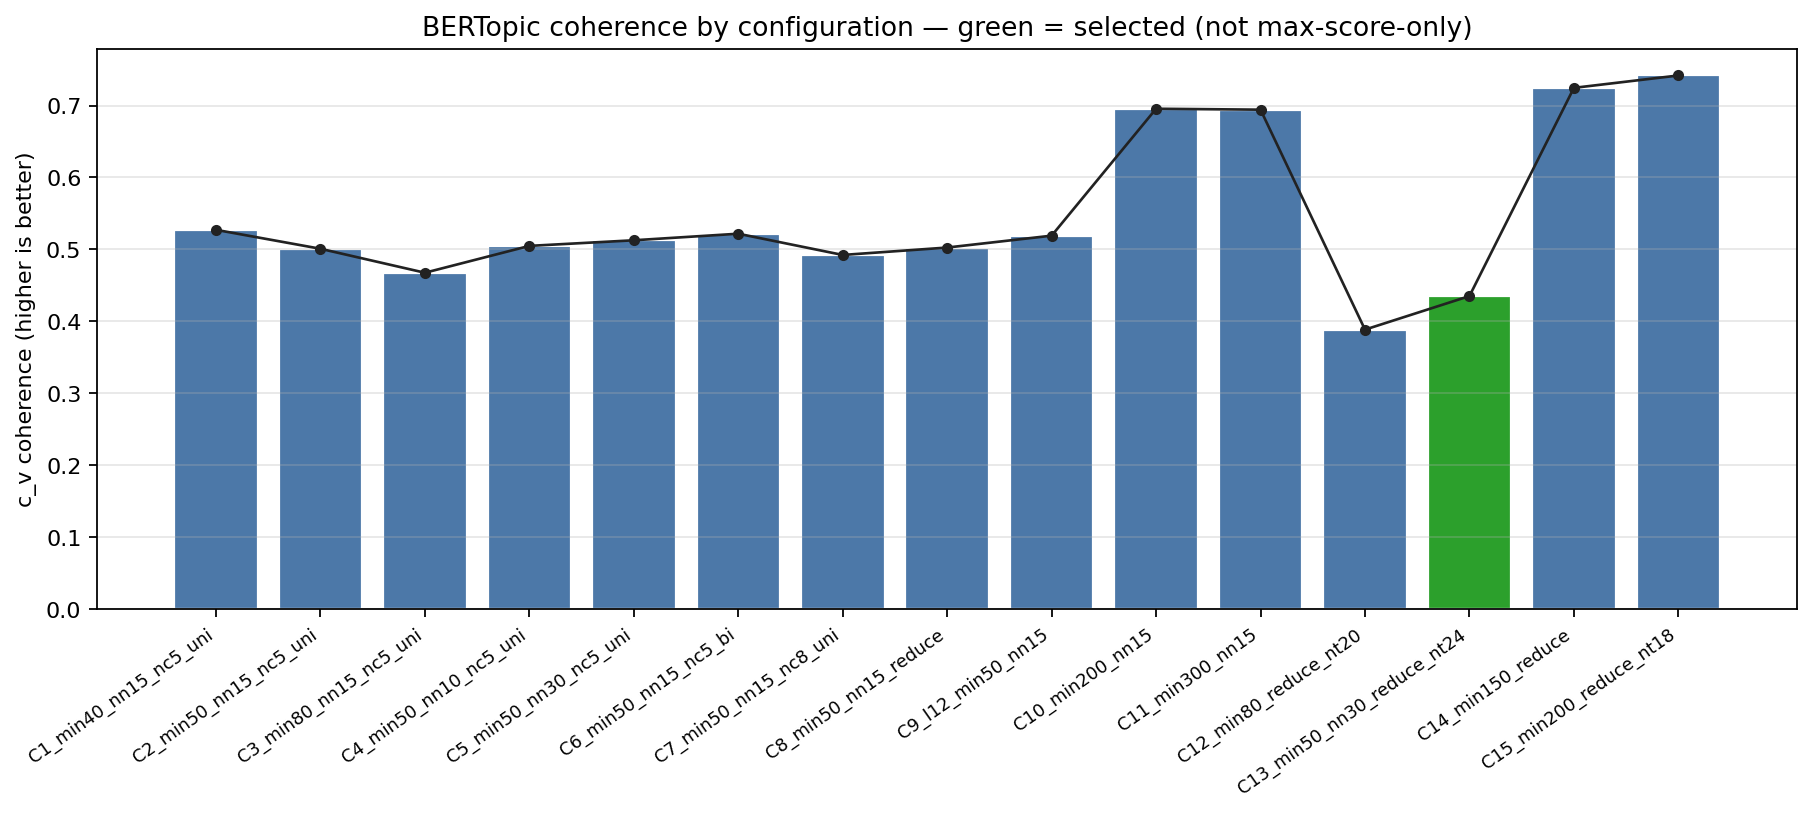

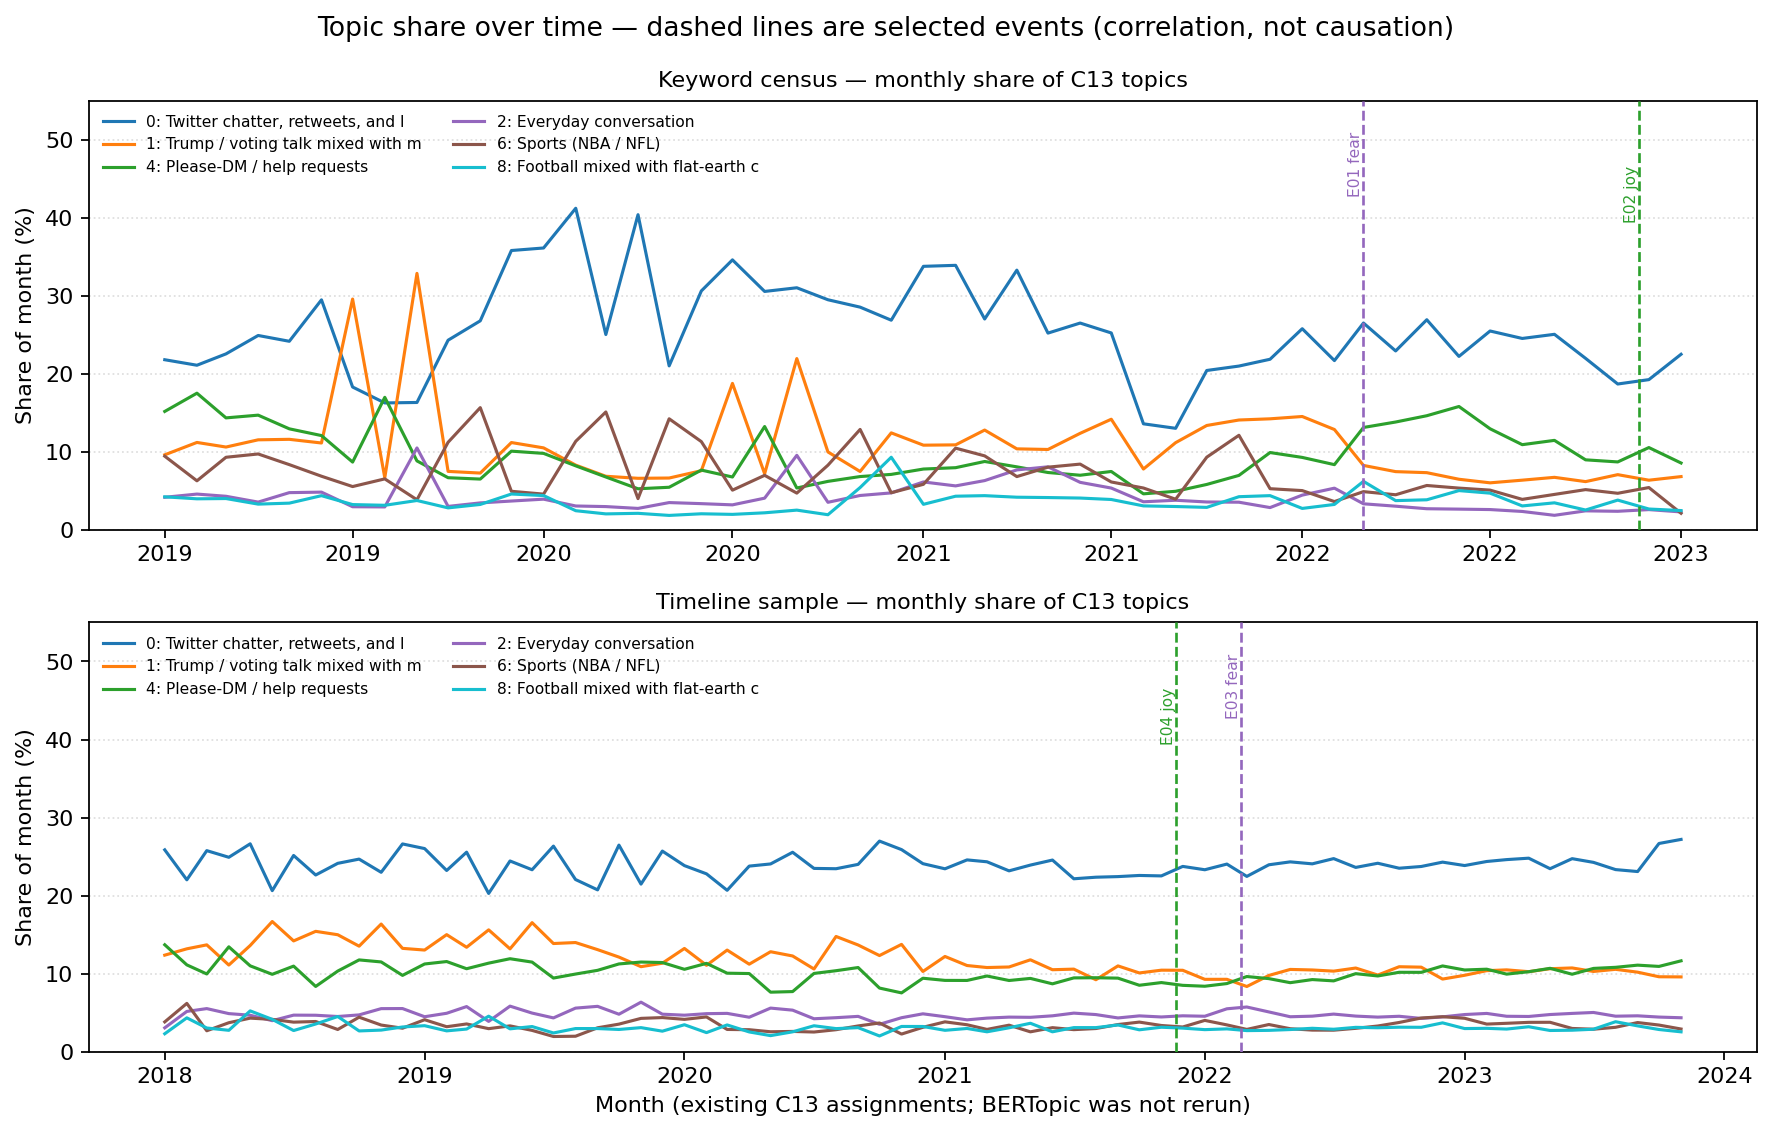

In [2]:
exp = pd.read_csv(OUT / "bertopic_experiments.csv", encoding="utf-8-sig")
topics = pd.read_csv(OUT / "final_topics.csv", encoding="utf-8-sig")
print("configurations", len(exp))
assert len(exp) == 15
display(exp)
named = topics[topics["topic_id"].astype(float) >= 0]
print("final_topics rows", len(topics), "named", len(named), "outlier_rows", len(topics) - len(named))
assert len(named) == 18
assert len(topics) == 19
display(topics[["topic_id", "topic_name", "topic_size", "percentage"] +
               [c for c in ["topic_words"] if c in topics.columns]])
if "ifb_topword_hits" in exp.columns:
    print("ifb_topword_hits sum", exp["ifb_topword_hits"].astype(float).sum())
display(Image(filename=str(OUT / "coherence_plot.png")))
display(Image(filename=str(OUT / "topic_over_time_monthly.png")))
print("DONE topic verification")
